<a href="https://colab.research.google.com/github/whitneymbakop/CRM-coursework-1/blob/main/CRM_TASK1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1.1 Ticker selection and data acquisition

In [3]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('yfinance:', yf.__version__)

pandas: 2.2.3
numpy: 2.4.6
yfinance: 0.2.66


In [4]:
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

retrieval_date = datetime.now().strftime('%Y-%m-%d %H:%M')
sp500_df.to_csv('sp500_tickers.csv', index=False)

print('Ticker list retrieved on:', retrieval_date)
print('Total tickers extracted:', len(tickers))
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Ticker list retrieved on: 2026-11-18 17:52
Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [5]:
start = '2021-01-01'
end = '2025-01-01'

data = yf.download(tickers, start=start, end=end, auto_adjust=False)

df = data['Adj Close']
close_df = data['Close']
volume_df = data['Volume']

market_prices = yf.download('^GSPC', start=start, end=end, auto_adjust=False)['Adj Close']

download_date = datetime.now().strftime('%Y-%m-%d %H:%M')

df.to_csv('adj_close.csv')
close_df.to_csv('close.csv')
volume_df.to_csv('volume.csv')
market_prices.to_csv('gspc.csv')

print('Prices downloaded on:', download_date)
print('Shape:', df.shape)
print('First date:', df.index.min().date(), '| Last date:', df.index.max().date())
print('Benchmark rows:', len(market_prices))

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'VYLR', 'FDXF', 'Q', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed


Prices downloaded on: 2026-11-18 17:54
Shape: (1005, 503)
First date: 2021-01-04 | Last date: 2024-12-31
Benchmark rows: 1005


In [6]:
failed = [t for t in tickers if df[t].isna().all()]
print('Tickers with no price data:', len(failed))
print(failed)

Tickers with no price data: 5
['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


1.2 Data validation and alignment

In [7]:
print('Duplicate dates (shares):', df.index.duplicated().sum())
print('Duplicate dates (benchmark):', market_prices.index.duplicated().sum())
print('Share and benchmark dates identical:', df.index.equals(market_prices.index))

Duplicate dates (shares): 0
Duplicate dates (benchmark): 0
Share and benchmark dates identical: True


In [8]:
log = []

for share in df.columns:
    prices = df[share]
    close = close_df[share]
    volume = volume_df[share]
    reason = ''

    if prices.isna().all():
        reason = 'no price data'
    elif pd.isna(prices.iloc[0]) or pd.isna(prices.iloc[-1]):
        reason = 'unequal history: ' + str(prices.first_valid_index().date()) + ' to ' + str(prices.last_valid_index().date())
    elif prices.isna().sum() > 0:
        reason = str(prices.isna().sum()) + ' missing prices'
    elif (prices <= 0).any() or (close <= 0).any():
        reason = 'nonpositive price'
    elif volume.isna().any() or (volume <= 0).any():
        reason = 'volume error (missing or zero volume)'

    log.append({'Share': share,
                'First_date': prices.first_valid_index(),
                'Last_date': prices.last_valid_index(),
                'Missing_prices': prices.isna().sum(),
                'Status': 'excluded' if reason else 'included',
                'Reason': reason})

log_df = pd.DataFrame(log).set_index('Share')
log_df.to_csv('exclusion_log.csv')

included = log_df[log_df['Status'] == 'included'].index.tolist()
print('Included:', len(included))
print('Excluded:', len(log_df) - len(included))
log_df[log_df['Status'] == 'excluded']

Included: 486
Excluded: 17


,First_date,Last_date,Missing_prices,Status,Reason
Share,,,,,
APP,2021-04-15,2024-12-31,70,excluded,unequal history: 2021-04-15 to 2024-12-31
CEG,2022-01-19,2024-12-31,263,excluded,unequal history: 2022-01-19 to 2024-12-31
COIN,2021-04-14,2024-12-31,69,excluded,unequal history: 2021-04-14 to 2024-12-31
EXE,2021-02-10,2024-12-31,26,excluded,unequal history: 2021-02-10 to 2024-12-31
FDXF,NaT,NaT,1005,excluded,no price data
FERG,2021-01-04,2024-12-31,0,excluded,volume error (missing or zero volume)
GEHC,2022-12-15,2024-12-31,492,excluded,unequal history: 2022-12-15 to 2024-12-31
GEV,2024-03-27,2024-12-31,812,excluded,unequal history: 2024-03-27 to 2024-12-31
HONA,NaT,NaT,1005,excluded,no price data


In [9]:
df1 = df.T
print('Before cleaning:', df1.shape)

df1 = df1.loc[included]
print('After cleaning:', df1.shape)

close_df = close_df[included]
volume_df = volume_df[included]

Before cleaning: (503, 1005)
After cleaning: (486, 1005)


In [10]:
daily_change = df[included].pct_change(fill_method=None)
all_moves = daily_change.stack()
big_moves = all_moves[all_moves.abs() > 0.40]
print('Daily Adj Close moves larger than 40%:', len(big_moves))
print(big_moves)

print(yf.Ticker('NVDA').splits.tail(3))
print(close_df['NVDA'].loc['2024-06-05':'2024-06-12'])

Daily Adj Close moves larger than 40%: 8
Date        Ticker
2022-08-05  CVNA      0.400716
2022-12-07  CVNA     -0.429210
2023-01-12  CVNA      0.460000
2023-06-08  CVNA      0.560206
2023-07-19  CVNA      0.402010
2024-04-11  GL       -0.531402
2024-07-26  DXCM     -0.406583
2024-11-15  BE        0.591867
dtype: float64
Date
2007-09-11 00:00:00-04:00     1.5
2021-07-20 00:00:00-04:00     4.0
2024-06-10 00:00:00-04:00    10.0
Name: Stock Splits, dtype: float64
Date
2024-06-05    122.440002
2024-06-06    120.998001
2024-06-07    120.888000
2024-06-10    121.790001
2024-06-11    120.910004
2024-06-12    125.199997
Name: NVDA, dtype: float64


1.3 Weekly return and weekly beta
1.3.1 Mean weekly return

In [14]:
def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()

    weekly_prices = weekly_prices.loc[(weekly_prices.index >= start) & (weekly_prices.index < end)]

    return weekly_prices.pct_change(fill_method=None)

In [12]:
weekly_returns = calculate_weekly_returns(df1).iloc[1:]

market_weekly = market_prices.resample("W-FRI").last()
market_weekly = market_weekly.loc[(market_weekly.index >= start) & (market_weekly.index < end)]
market_weekly_returns = market_weekly.pct_change(fill_method=None).iloc[1:].squeeze()

print('First week:', weekly_returns.index.min().date(), '| Last week:', weekly_returns.index.max().date())
print('Weekly observations:', len(weekly_returns))
print('Missing weekly returns:', weekly_returns.isna().sum().sum())
print('Same week labels as benchmark:', weekly_returns.index.equals(market_weekly_returns.index))

days_per_week = market_prices.resample('W-FRI').size()
print('Holiday-shortened weeks kept:', (days_per_week.loc[weekly_returns.index] < 5).sum())

weekly_returns.to_csv('weekly_returns.csv')

First week: 2021-01-15 | Last week: 2024-12-27
Weekly observations: 207
Missing weekly returns: 0
Same week labels as benchmark: True
Holiday-shortened weeks kept: 37


In [13]:
mean_weekly_return = weekly_returns.mean()

print('Mean weekly return across shares (%):')
print((mean_weekly_return * 100).describe().round(3))
print('Benchmark mean weekly return (%):', round(market_weekly_returns.mean() * 100, 3))

w0 = df['AAPL'].loc['2021-01-04':'2021-01-08'].iloc[-1]
w1 = df['AAPL'].loc['2021-01-11':'2021-01-15'].iloc[-1]
print('AAPL by hand:', round(w1 / w0 - 1, 6), '| from code:', round(weekly_returns['AAPL'].iloc[0], 6))

Mean weekly return across shares (%):
count    486.000
mean       0.286
std        0.265
min       -0.447
25%        0.118
50%        0.262
75%        0.421
max        1.777
dtype: float64
Benchmark mean weekly return (%): 0.24
AAPL by hand: -0.037183 | from code: -0.037183


1.3.2 Weekly beta

In [15]:
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [16]:
beta_df = calculate_weekly_beta(weekly_returns, market_weekly_returns)

print('Aligned weekly observations per share:', beta_df['Paired_weeks'].unique())
print('Shares with missing beta:', beta_df['Beta'].isna().sum())
print(beta_df['Beta'].describe().round(3))

for share in ['AAPL', 'MSFT', 'JNJ']:
    slope = np.polyfit(market_weekly_returns, weekly_returns[share], 1)[0]
    print(share, '| beta:', round(beta_df.loc[share, 'Beta'], 4), '| polyfit slope:', round(slope, 4))

Aligned weekly observations per share: [207]
Shares with missing beta: 0
count    486.000
mean       0.974
std        0.407
min        0.055
25%        0.667
50%        0.951
75%        1.180
max        3.779
Name: Beta, dtype: float64
AAPL | beta: 1.1748 | polyfit slope: 1.1748
MSFT | beta: 1.1286 | polyfit slope: 1.1286
JNJ | beta: 0.3051 | polyfit slope: 0.3051


In [17]:
gspc = yf.download('^GSPC', start=start, end=end, auto_adjust=False)
print('Largest |Adj Close - Close| for ^GSPC:', (gspc['Adj Close'].squeeze() - gspc['Close'].squeeze()).abs().max())

close_weekly_returns = calculate_weekly_returns(close_df.T).iloc[1:]
beta_close_df = calculate_weekly_beta(close_weekly_returns, market_weekly_returns)

difference = (beta_df['Beta'] - beta_close_df['Beta']).abs()
print('Correlation, beta (Adj Close) vs beta (Close):', round(beta_df['Beta'].corr(beta_close_df['Beta']), 4))
print('Median difference:', round(difference.median(), 4), '| Largest difference:', round(difference.max(), 4))

beta_df.to_csv('weekly_beta.csv')

[*********************100%***********************]  1 of 1 completed


Largest |Adj Close - Close| for ^GSPC: 0.0
Correlation, beta (Adj Close) vs beta (Close): 0.9999
Median difference: 0.0013 | Largest difference: 0.0171


1.4 Adapted RFM calculations

In [18]:
complete = df[included].notna().all(axis=1) & volume_df.notna().all(axis=1)
obs_date = df.index[complete].max()
print('Observation date:', obs_date.date())

average_volume = volume_df.shift(1).rolling(20).mean()

high_volume = volume_df > 2 * average_volume
print('High-volume days found (all shares):', high_volume.sum().sum())

share = 'AAPL'
i = 100
by_hand = volume_df[share].iloc[i - 20:i].mean()
print(share, 'baseline on', volume_df.index[i].date(), '| by hand:', round(by_hand), '| from code:', round(average_volume[share].iloc[i]))

Observation date: 2024-12-31
High-volume days found (all shares): 18280
AAPL baseline on 2021-05-27 | by hand: 90346935 | from code: 90346935


1.4.1 Recency

In [19]:
recency = {}
last_event = {}

for share in volume_df.columns:
    event_days = high_volume.index[high_volume[share]]
    event_days = event_days[event_days <= obs_date]

    if len(event_days) > 0:
        last_event[share] = event_days[-1]
        recency[share] = (obs_date - event_days[-1]).days
    else:
        last_event[share] = None
        recency[share] = np.nan

rfm_df = pd.DataFrame({'Last_event': last_event, 'Recency': recency})

print('Shares with no high-volume day (R missing):', rfm_df['Recency'].isna().sum())
print(rfm_df.index[rfm_df['Recency'].isna()].tolist())
print('Shares with an event on the observation date (R = 0):', (rfm_df['Recency'] == 0).sum())
print(rfm_df['Recency'].describe().round(1))

Shares with no high-volume day (R missing): 0
[]
Shares with an event on the observation date (R = 0): 0
count    486.0
mean      20.4
std       21.3
min        4.0
25%       11.0
50%       11.0
75%       14.8
max      222.0
Name: Recency, dtype: float64


In [20]:
ex = pd.DataFrame({'Volume': volume_df['AAPL'],
                   'Avg_prev_20': average_volume['AAPL'],
                   'Threshold_2x': 2 * average_volume['AAPL'],
                   'High_volume': high_volume['AAPL']})

print('Last 3 high-volume days for AAPL:')
print(ex[ex['High_volume']].tail(3))
print('\nObservation date:', obs_date.date())
print('Latest event:', rfm_df.loc['AAPL', 'Last_event'].date())
print('Recency (calendar days):', rfm_df.loc['AAPL', 'Recency'])

Last 3 high-volume days for AAPL:
               Volume  Avg_prev_20  Threshold_2x  High_volume
Date                                                         
2024-09-20  318679900   47003055.0    94006110.0         True
2024-11-25   90152800   43820740.0    87641480.0         True
2024-12-20  147495300   45004605.0    90009210.0         True

Observation date: 2024-12-31
Latest event: 2024-12-20
Recency (calendar days): 11


1.4.2 Frequency

In [21]:
last60 = volume_df.loc[:obs_date].index[-60:]
print('60-session window:', last60[0].date(), 'to', last60[-1].date(), '| sessions:', len(last60))

print('Shares with a full baseline across the window:', average_volume.loc[last60].notna().all().sum(), 'of', len(volume_df.columns))

rfm_df['Frequency'] = high_volume.loc[last60].sum()

print(rfm_df['Frequency'].describe().round(1))
print('\nNumber of shares with each Frequency value:')
print(rfm_df['Frequency'].value_counts().sort_index())

60-session window: 2024-10-07 to 2024-12-31 | sessions: 60
Shares with a full baseline across the window: 486 of 486
count    486.0
mean       3.0
std        1.3
min        0.0
25%        2.0
50%        3.0
75%        4.0
max        8.0
Name: Frequency, dtype: float64

Number of shares with each Frequency value:
Frequency
0     10
1     42
2    130
3    149
4     94
5     45
6     11
7      3
8      2
Name: count, dtype: int64


In [22]:
window = ex.loc[last60]
print('AAPL high-volume days in the 60-session window:')
print(window[window['High_volume']])
print('\nFrequency for AAPL:', rfm_df.loc['AAPL', 'Frequency'])

AAPL high-volume days in the 60-session window:
               Volume  Avg_prev_20  Threshold_2x  High_volume
Date                                                         
2024-11-25   90152800   43820740.0    87641480.0         True
2024-12-20  147495300   45004605.0    90009210.0         True

Frequency for AAPL: 2


1.4.3 Monetary

In [23]:
daily_traded_value = close_df.loc[last60] * volume_df.loc[last60]
rfm_df['Monetary'] = daily_traded_value.sum()

print('Missing Close or Volume in the window:', daily_traded_value.isna().sum().sum())
print(rfm_df['Monetary'].describe().round(2))

print('\nHighest M:')
print(rfm_df['Monetary'].sort_values(ascending=False).head(5).round(2))
print('\nLowest M:')
print(rfm_df['Monetary'].sort_values().head(5).round(2))

Missing Close or Volume in the window: 0
count    4.860000e+02
mean     3.940419e+10
std      1.291388e+11
min      1.297483e+09
25%      1.019517e+10
50%      1.668382e+10
75%      3.227689e+10
max      1.847697e+12
Name: Monetary, dtype: float64

Highest M:
TSLA    1.847697e+12
NVDA    1.825337e+12
AAPL    6.233034e+11
MSFT    5.348982e+11
AMZN    4.681770e+11
Name: Monetary, dtype: float64

Lowest M:
NWS     1.297483e+09
ECHO    2.348329e+09
FOX     2.708141e+09
IVZ     3.693970e+09
L       3.708510e+09
Name: Monetary, dtype: float64


In [24]:
aapl = pd.DataFrame({'Close': close_df.loc[last60, 'AAPL'],
                     'Volume': volume_df.loc[last60, 'AAPL']})
aapl['Close_x_Volume'] = aapl['Close'] * aapl['Volume']

print(aapl.head(3))
print('M for AAPL:', round(rfm_df.loc['AAPL', 'Monetary'], 2))

                 Close    Volume  Close_x_Volume
Date                                            
2024-10-07  221.690002  39505400    8.757952e+09
2024-10-08  225.770004  31855700    7.192062e+09
2024-10-09  229.539993  33591100    7.710501e+09
M for AAPL: 623303377706.58


In [25]:
print(pd.DataFrame({'Close': close_df['NVDA'], 'Volume': volume_df['NVDA']}).loc['2024-06-05':'2024-06-12'])

                 Close     Volume
Date                             
2024-06-05  122.440002  528402000
2024-06-06  120.998001  664696000
2024-06-07  120.888000  412386000
2024-06-10  121.790001  313434100
2024-06-11  120.910004  222551200
2024-06-12  125.199997  299595000


1.5 Metric interpretation and supporting evidence

In [26]:
sp500_df['Ticker'] = tickers
info = sp500_df.set_index('Ticker')

features = pd.DataFrame({
    'Security': info['Security'],
    'Sector': info['GICS Sector'],
    'Mean_weekly_return': mean_weekly_return,
    'Beta': beta_df['Beta'],
    'Weeks': beta_df['Paired_weeks'],
    'Recency': rfm_df['Recency'],
    'Frequency': rfm_df['Frequency'],
    'Monetary': rfm_df['Monetary']
})
features = features.loc[included]

print('Shares in feature table:', len(features))
print('Shares with all five features (common set):', len(features.dropna()))

features.to_csv('feature_table.csv')
features[['Mean_weekly_return', 'Beta', 'Recency', 'Frequency', 'Monetary']].describe().round(4)

Shares in feature table: 486
Shares with all five features (common set): 486


,Mean_weekly_return,Beta,Recency,Frequency,Monetary
count,486.0000,486.0000,486.0000,486.0000,4.860000e+02
mean,0.0029,0.9737,20.4074,2.9897,3.940419e+10
std,0.0027,0.4073,21.3424,1.3308,1.291388e+11
min,-0.0045,0.0555,4.0000,0.0000,1.297483e+09
25%,0.0012,0.6666,11.0000,2.0000,1.019517e+10
50%,0.0026,0.9506,11.0000,3.0000,1.668382e+10
75%,0.0042,1.1795,14.7500,4.0000,3.227689e+10
max,0.0178,3.7786,222.0000,8.0000,1.847697e+12


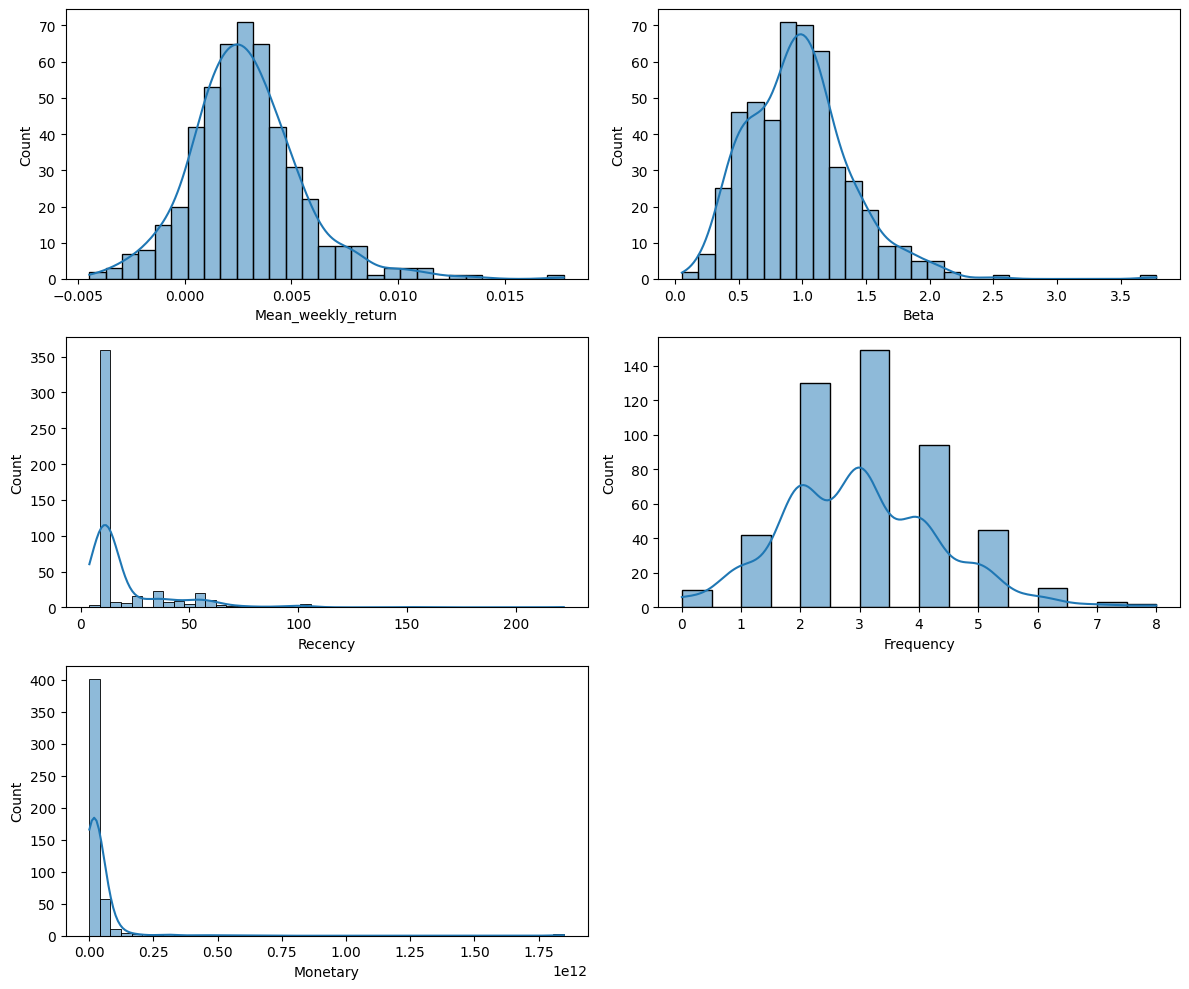

In [27]:
plt.figure(figsize=(12, 10))
plt.subplot(3, 2, 1); sns.histplot(features['Mean_weekly_return'], kde=True)
plt.subplot(3, 2, 2); sns.histplot(features['Beta'], kde=True)
plt.subplot(3, 2, 3); sns.histplot(features['Recency'], kde=True)
plt.subplot(3, 2, 4); sns.histplot(features['Frequency'], kde=True)
plt.subplot(3, 2, 5); sns.histplot(features['Monetary'], kde=True)
plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150)
plt.show()